# Predicción de tráfico vehicular y estimación de ingresos de peaje – Trabajo de integrador
Concesión vial Buga – Tuluá – La Paila – La Victoria · Metodología CRISP-DM





## FASE 1 · Comprensión del negocio

**Problema.** La estimación de los ingresos de peaje de una concesión de primera generación depende de proyectar bien el tráfico; los métodos tradicionales (series de tiempo y regresión) tienen limitaciones ante eventos atípicos como el cambio de clima o la pandemia y relaciones no lineales.

**Objetivo.** Construir y comparar modelos predictivos del tráfico mensual del tramo y, con el mejor, proyectar los ingresos por recaudo:

$$\text{Ingresos} = \sum_{i=1}^{5} \text{Tráfico}_i \cdot \text{Tarifa}_i + \sum_{EA=1}^{4} \text{Ejes}_{EA}\cdot \text{Tarifa}_{EA} \qquad \text{Tarifa}_T = \text{Tarifa}_{T-1}\,(1+\text{Var.\%IPC}_{T-1})\ \ (\text{redondeada a la centena})$$

**Criterios de éxito (definidos antes de modelar).**
1. El mejor modelo debe superar al *naive estacional* (mismo mes del año anterior) en MAPE sobre la validación temporal.
2. Se reporta MAE, RMSE y MAPE por horizonte (1-3, 4-6, 7-12 meses).
3. Se produce la proyección de ingresos por categoría, periodo y escenario (optimista, base, pesimista) y un análisis de sensibilidad.

**Alcance y supuestos.** El ingreso calculado es *teórico* (vehículos × tarifa): no descuenta exentos ni evasión. Las categorías sin tarifa publicada se asumen sin ingreso.

## FASE 2 · Comprensión de los datos

In [ ]:
import warnings, itertools, time, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dateutil.easter import easter
import holidays

try:
    from statsmodels.tsa.seasonal import STL
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    from statsmodels.tsa.holtwinters import ExponentialSmoothing
    HAS_SM = True
except ImportError:
    HAS_SM = False
    print("statsmodels no está instalado: se omiten STL, SARIMA/SARIMAX y Holt-Winters.")


warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40)

DATA_DIR = "/content"
OUT_DIR = "/content/resultados"       # <- carpeta de resultados
os.makedirs(OUT_DIR, exist_ok=True)

F_TRAFICO = f"{DATA_DIR}/BD_TraficoTotal.xlsx"
F_TARIFA = f"{DATA_DIR}/BD_Tarifa.xlsx"
F_IPC = f"{DATA_DIR}/BD_Inflación.xlsx"
F_PUERTO = f"{DATA_DIR}/Trafico_Portuario_Marítimo_En_Colombia_20260923.csv"
F_ISE = f"{DATA_DIR}/anex-ISE-9actividades-ago2026.xlsx"



VENTANA_INICIO = "2006-01-01"            # ventana de modelado (la serie tiene datos reales desde 2004)
# Eventos atípicos (ajusta las fechas si lo consideras necesario)
COVID = ("2020-03-01", "2020-12-01")     # confinamiento y recuperación
PARO = ("2021-04-01", "2021-06-01")      # paro nacional / bloqueos (afectó Valle y Buenaventura)

In [ ]:
import os

def a_mes(s):
    """Normaliza cualquier fecha al primer día de su mes."""
    return pd.to_datetime(s).dt.to_period("M").dt.to_timestamp()

# Ajustar rutas de archivos si están en /content/sample_data
paths = ["F_TRAFICO", "F_TARIFA", "F_IPC", "F_PUERTO", "F_ISE"]
for p_var in paths:
    actual_path = globals()[p_var]
    if not os.path.exists(actual_path):
        fallback = actual_path.replace("/content/", "/content/sample_data/")
        if os.path.exists(fallback):
            globals()[p_var] = fallback

# --- 1.1 Tráfico por estación, mes y categoría (formato largo) ---
tr = pd.read_excel(F_TRAFICO)
tr.columns = ["estacion", "fecha", "categoria", "vehiculos"]
tr["fecha"] = a_mes(tr["fecha"]
)
# --- 1.2 Tarifas por estación, año y categoría ---
tf = pd.read_excel(F_TARIFA)
tf.columns = ["estacion", "anio", "categoria", "tarifa"]

# --- 1.3 IPC (índice y variación 12 meses) ---
ipc = pd.read_excel(F_IPC)
ipc.columns = ["fecha", "ipc_indice", "ipc_var12"]
ipc["fecha"] = a_mes(ipc["fecha"])

# --- 1.4 Tráfico portuario de Buenaventura ---
# El CSV viene separado por ";" y con el punto como separador de miles (ej. 64.461 = 64461; 2.021 = 2021)
pt = pd.read_csv(F_PUERTO, sep=";", dtype=str)
pt.columns = pt.columns.str.strip()
cols_carga = ["EXPORTACION", "IMPORTACIÓN", "TRANSBORDO", "TRANSITO INTERNACIONAL",
              "FLUVIAL", "CABOTAJE", "MOVILIZACIONES A BORDO", "TRANSITORIA"]
for c in cols_carga + ["AÑO VIGENCIA", "MES VIGENCIA"]:
    pt[c] = pd.to_numeric(pt[c].str.strip().str.replace(".", "", regex=False))
pt["fecha"] = pd.to_datetime(dict(year=pt["AÑO VIGENCIA"], month=pt["MES VIGENCIA"], day=1))
pt["ton_total"] = pt[cols_carga].sum(axis=1)

port = pt.groupby("fecha").agg(
    port_total=("ton_total", "sum"),
    port_export=("EXPORTACION", "sum"),
    port_import=("IMPORTACIÓN", "sum"),
    port_registros=("ton_total", "size"),
)
port["port_contenedores"] = pt[pt["TIPO DE CARGA"].str.strip() == "CONTENEDORES"].groupby("fecha")["ton_total"].sum()
port["port_contenedores"] = port["port_contenedores"].fillna(0)


# --- 1.5 ISE (DANE)
MESES_ES = {"Enero": 1, "Febrero": 2, "Marzo": 3, "Abril": 4, "Mayo": 5, "Junio": 6, "Julio": 7,
            "Agosto": 8, "Septiembre": 9, "Octubre": 10, "Noviembre": 11, "Diciembre": 12}

def leer_cuadro_ise(path, hoja):
    '''Lee un cuadro del anexo del ISE (años en una fila, meses en la siguiente) y devuelve un DataFrame mensual.'''
    import openpyxl
    filas = list(openpyxl.load_workbook(path, read_only=True, data_only=True)[hoja].iter_rows(values_only=True))
    i0 = next(i for i, r in enumerate(filas) if r[0] == "Concepto")
    anios, meses = filas[i0], filas[i0 + 1]
    cols, anio = [], None
    for j in range(1, len(meses)):
        if anios[j] is not None:                                   # los años vienen como 2024p, 2026pr, etc.
            anio = int("".join(ch for ch in str(anios[j]) if ch.isdigit())[:4])
        if meses[j] in MESES_ES:
            cols.append((j, pd.Timestamp(anio, MESES_ES[meses[j]], 1)))
    datos = {}
    for r in filas[i0 + 2:]:
        if r[0] and str(r[0]).startswith("Fuente"):
            break
        if r[0]:
            datos[r[0]] = [r[j] for j, _ in cols]
    return pd.DataFrame(datos, index=[f for _, f in cols]).astype(float)

ise_o = leer_cuadro_ise(F_ISE, "Cuadro 1")      # serie original
ise_d = leer_cuadro_ise(F_ISE, "Cuadro 2")      # ajustada por efecto estacional y calendario
COL_ISE = [c for c in ise_o.columns if c.startswith("Indicador de Seguimiento")][0]
COL_CT = [c for c in ise_o.columns if c.startswith("Comercio al por mayor")][0]     # comercio, transporte, alojamiento
COL_IND = [c for c in ise_o.columns if c.startswith("Industrias manufactureras")][0]
ise = pd.DataFrame({"ise": ise_o[COL_ISE], "ise_sa": ise_d[COL_ISE],
                    "ise_comercio_transp": ise_o[COL_CT], "ise_industria": ise_o[COL_IND]})

# --- 1.6 Chequeos de calidad ---

print("Tráfico:", tr.shape, "| duplicados:", tr.duplicated(["estacion", "fecha", "categoria"]).sum(),
      "| nulos:", tr.isna().sum().sum())
print("Estaciones:", tr["estacion"].unique().tolist(), "| categorías:", tr["categoria"].nunique())
print("Tarifas:", tf.shape, "| duplicados:", tf.duplicated(["estacion", "anio", "categoria"]).sum())
print("Puerto:", port.index.min().date(), "→", port.index.max().date(), "| meses:", len(port))
print("ISE:", ise.index.min().date(), "→", ise.index.max().date(), "| meses:", len(ise), "| nulos:", int(ise.isna().sum().sum()))

Tráfico: (10640, 4) | duplicados: 0 | nulos: 0
Estaciones: ['Betania', 'Uribe'] | categorías: 14
Tarifas: (896, 4) | duplicados: 0
Puerto: 2018-01-01 → 2026-06-01 | meses: 102
ISE: 2005-01-01 → 2026-08-01 | meses: 260 | nulos: 0


## FASE 3 · Preparación y análisis de los datos  *(Objetivo específico 1)*
### 3.1 Dataset maestro mensual
Se agrega todo a **frecuencia mensual**. La variable objetivo es el **tráfico total** (suma de estaciones). Internamente se modela el **TPD** (tráfico promedio diario = total / días del mes) para que los meses de 28, 30 y 31 días sean comparable

In [ ]:
LIVIANOS = ["Cat. I", "Cat. I E", "Cat. II", "Cat. II E"]
tr["grupo"] = np.where(tr["categoria"].isin(LIVIANOS), "livianos", "pesados")

idx = pd.date_range("1995-01-01", tr["fecha"].max(), freq="MS")
m = pd.DataFrame(index=idx)
m.index.name = "fecha"

por_est = tr.pivot_table(index="fecha", columns="estacion", values="vehiculos", aggfunc="sum")
por_grp = tr.pivot_table(index="fecha", columns="grupo", values="vehiculos", aggfunc="sum")
m["trafico_total"] = por_est.sum(axis=1)
for e in por_est.columns:
    m[f"trafico_{e.lower()}"] = por_est[e]
m["trafico_livianos"] = por_grp["livianos"]
m["trafico_pesados"] = por_grp["pesados"]
m["trafico_cat5"] = tr[tr["categoria"] == "Cat. V"].groupby("fecha")["vehiculos"].sum()

# La serie tiene ceros hasta que empieza el registro real: se descartan esos meses
primer_mes = m.index[m["trafico_total"] > 0].min()
m = m.loc[primer_mes:].copy()
print("Primer mes con tráfico registrado:", primer_mes.date(), "| último:", m.index.max().date())

# IPC y tarifas
m = m.join(ipc.set_index("fecha")[["ipc_indice", "ipc_var12"]])
m = m.join(ise)                                                            # >>> NUEVO: ISE (DANE)
t1 = tf[tf["categoria"] == "Cat. I"].pivot_table(index="anio", columns="estacion", values="tarifa")
t1.columns = [f"tarifa_cat1_{c.lower()}" for c in t1.columns]
m["anio"] = m.index.year                                                   # >>> MODIFICADO: evita la columna sobrante key_0
m = m.join(t1, on="anio").drop(columns="anio")
m["tarifa_cat1_prom"] = m[t1.columns].mean(axis=1)
m["tarifa_cat1_real"] = m["tarifa_cat1_prom"] * ipc["ipc_indice"].iloc[-1] / m["ipc_indice"]   # $ constantes del último mes

# Ingreso teórico = vehículos × tarifa (estación, año, categoría)
x = tr.assign(anio=tr["fecha"].dt.year).merge(tf, on=["estacion", "anio", "categoria"], how="left")
# Las categorías "E" de la estación Uribe no tienen tarifa en BD_Tarifa (y las "Eje" solo faltan en 1995-1998).
# Supuesto: sin tarifa publicada = no genera ingreso. Es prácticamente nulo (<0,01% del tráfico); confírmalo con tu asesora.
sin_tarifa = x[x["tarifa"].isna() & (x["fecha"] >= primer_mes)]
print("Tráfico (≥2004) sin tarifa:", f"{sin_tarifa['vehiculos'].sum() / x[x['fecha'] >= primer_mes]['vehiculos'].sum():.2%}",
      "→", sin_tarifa.groupby(["estacion", "categoria"]).size().index.tolist())
x["ingreso"] = x["vehiculos"] * x["tarifa"].fillna(0)
m["ingreso_teorico"] = x.groupby("fecha")["ingreso"].sum()
m["tarifa_media_pond"] = m["ingreso_teorico"] / m["trafico_total"]

# Puerto de Buenaventura (solo existe 2018-01 → 2026-06)
m = m.join(port)

# Calendario (conocido hacia el futuro): festivos, fines de semana, Semana Santa
def calendario(indice):
    anios = range(indice.year.min(), indice.year.max() + 2)
    co = holidays.CO(years=anios)
    filas = []
    for d in indice:
        dias = pd.date_range(d, d + pd.offsets.MonthEnd(0))
        jueves_santo = pd.Timestamp(easter(d.year)) - pd.Timedelta(days=3)
        filas.append(dict(
            dias=len(dias),
            n_festivos=sum(x.date() in co for x in dias),
            n_findes=int((dias.dayofweek >= 5).sum()),
            semana_santa=int(jueves_santo.year == d.year and jueves_santo.month == d.month),
        ))
    return pd.DataFrame(filas, index=indice)

def eventos(indice):
    e = pd.DataFrame(index=indice)
    e["covid"] = ((indice >= COVID[0]) & (indice <= COVID[1])).astype(int)
    e["paro"] = ((indice >= PARO[0]) & (indice <= PARO[1])).astype(int)
    return e

m = m.join(calendario(m.index)).join(eventos(m.index))
m["tpd"] = m["trafico_total"] / m["dias"]

print(m.shape)
m.tail(6).T

Primer mes con tráfico registrado: 2004-01-01 | último: 2026-08-01
Tráfico (≥2004) sin tarifa: 0.00% → [('Uribe', 'Cat. I E'), ('Uribe', 'Cat. II E'), ('Uribe', 'Cat. III E'), ('Uribe', 'Cat. IV E'), ('Uribe', 'Cat. V E')]
(272, 30)


fecha,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01
trafico_total,1.208608e+06,1.217684e+06,1.156944e+06,1.177588e+06,1.273180e+06,1.147628e+06
trafico_betania,6.724810e+05,6.781050e+05,6.458380e+05,6.529500e+05,7.043820e+05,6.399170e+05
trafico_uribe,5.361270e+05,5.395790e+05,5.111060e+05,5.246380e+05,5.687980e+05,5.077110e+05
trafico_livianos,9.412520e+05,9.478600e+05,8.931960e+05,9.164720e+05,9.863650e+05,8.859530e+05
trafico_pesados,2.673560e+05,2.698240e+05,2.637480e+05,2.611160e+05,2.868150e+05,2.616750e+05
trafico_cat5,1.352490e+05,1.354060e+05,1.324060e+05,1.352450e+05,1.438230e+05,1.297470e+05
ipc_indice,1.569400e+02,1.581700e+02,1.589100e+02,1.595300e+02,1.597900e+02,1.604200e+02
ipc_var12,5.555556e-02,5.686222e-02,5.841215e-02,6.141051e-02,6.024816e-02,6.245447e-02
ise,1.289195e+02,1.241604e+02,1.293941e+02,1.272999e+02,1.317049e+02,1.272660e+02
ise_sa,1.283064e+02,1.285624e+02,1.301910e+02,1.286916e+02,1.296853e+02,1.256468e+02


### 3.2 Guardar el dataset maestro y el diccionario de variables

In [ ]:
diccionario = pd.DataFrame([
    ("fecha", "Primer día del mes"),
    ("trafico_total", "VARIABLE OBJETIVO: vehículos del mes (Betania + Uribe, todas las categorías)"),
    ("trafico_betania / trafico_uribe", "Vehículos por estación"),
    ("trafico_livianos / trafico_pesados", "Livianos = Cat. I, I E, II, II E; pesados = el resto de categorías y ejes"),
    ("trafico_cat5", "Vehículos Cat. V (camiones pesados, el segmento más ligado a carga portuaria)"),
    ("ipc_indice / ipc_var12", "IPC (índice empalmado DANE) y variación anual"),
    ("ise", "ISE – Indicador de Seguimiento a la Economía (DANE), serie original, índice base 2015 = 100"),   # >>> NUEVO
    ("ise_sa", "ISE ajustado por efecto estacional y calendario (se revisa en cada publicación)"),            # >>> NUEVO
    ("ise_comercio_transp", "ISE de la agrupación Comercio, reparación de vehículos, transporte y almacenamiento, alojamiento y comidas"),  # >>> NUEVO
    ("ise_industria", "ISE de la agrupación Industrias manufactureras y construcción"),                      # >>> NUEVO
    ("tarifa_cat1_*", "Tarifa de Cat. I por estación y promedio (COP corrientes del año)"),
    ("tarifa_cat1_real", "Tarifa Cat. I promedio en pesos constantes del último mes"),
    ("ingreso_teorico", "Σ vehículos × tarifa (estación, año, categoría). No es recaudo real: no descuenta exentos ni evasión"),
    ("tarifa_media_pond", "ingreso_teorico / trafico_total"),
    ("port_total / port_export / port_import", "Carga movilizada en puerto de Buenaventura (suma de sociedades portuarias; unidad del CSV, presumiblemente toneladas)"),
    ("port_contenedores", "Carga en contenedores (Buenaventura)"),
    ("port_registros", "N° de filas del CSV por mes (sirve para detectar meses incompletos)"),
    ("dias / n_festivos / n_findes / semana_santa", "Calendario del mes (festivos de Colombia, sábados+domingos, mes del Jueves Santo)"),
    ("covid / paro", "Dummies de eventos atípicos (definidos en la configuración)"),
    ("tpd", "Tráfico medio diario = trafico_total / dias"),
], columns=["variable", "descripcion"])

m.reset_index().to_csv(f"{OUT_DIR}/dataset_maestro_mensual.csv", index=False)
with pd.ExcelWriter(f"{OUT_DIR}/dataset_maestro_mensual.xlsx") as w:
    m.reset_index().to_excel(w, sheet_name="maestro", index=False)
    diccionario.to_excel(w, sheet_name="diccionario", index=False)
print("Dataset guardado")

Dataset guardado


### 3.3 Análisis exploratorio

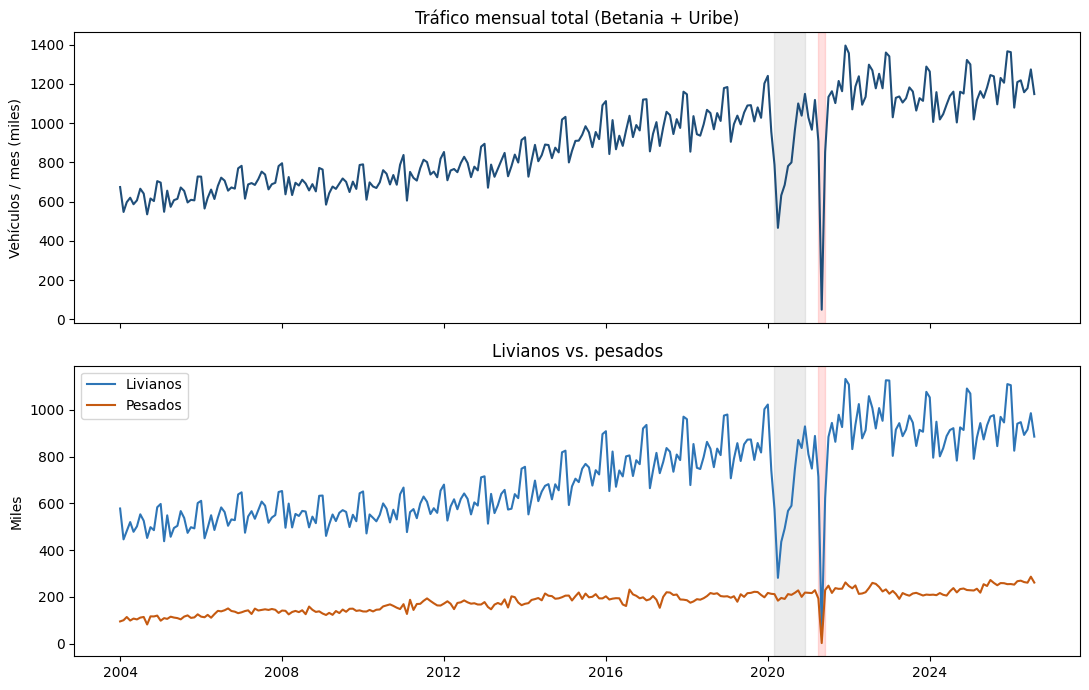

Índice estacional (TPD mes / TPD promedio del año), 2006-2019:
fecha
1     1.093
2     0.925
3     0.955
4     0.977
5     0.931
6     1.007
7     1.031
8     1.009
9     0.968
10    0.996
11    0.992
12    1.117


In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(m.index, m["trafico_total"] / 1e3, color="#1f4e79")
ax[0].set_ylabel("Vehículos / mes (miles)"); ax[0].set_title("Tráfico mensual total (Betania + Uribe)")
ax[1].plot(m.index, m["trafico_livianos"] / 1e3, label="Livianos", color="#2e75b6")
ax[1].plot(m.index, m["trafico_pesados"] / 1e3, label="Pesados", color="#c55a11")
ax[1].set_ylabel("Miles"); ax[1].legend(); ax[1].set_title("Livianos vs. pesados")
for a in ax:
    a.axvspan(pd.Timestamp(COVID[0]), pd.Timestamp(COVID[1]), color="grey", alpha=.15)
    a.axvspan(pd.Timestamp(PARO[0]), pd.Timestamp(PARO[1]), color="red", alpha=.12)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig1_serie_historica.png", dpi=130); plt.show()

# Estacionalidad: TMD relativo a la media anual
z = m.loc["2006":"2019", "tpd"]
perfil = (z / z.groupby(z.index.year).transform("mean")).groupby(z.index.month).mean()
print("Índice estacional (TPD mes / TPD promedio del año), 2006-2019:")
print(perfil.round(3).to_string())

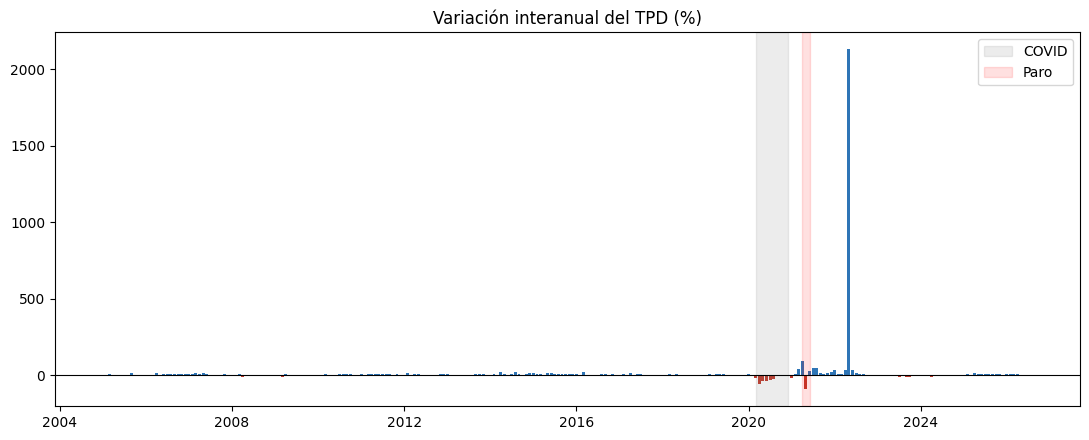

                tpd  yoy_tpd
fecha                       
2020-02-01  32976.6      2.1
2020-03-01  25409.3    -20.8
2020-04-01  15532.3    -55.1
2020-05-01  20373.7    -36.4
2020-06-01  22823.5    -35.0
2020-07-01  25174.3    -28.4
2020-08-01  25787.8    -26.7
2020-09-01  32138.2     -4.4
2020-10-01  35481.7      1.9
2020-11-01  34587.8      1.1
2020-12-01  37050.8     -4.4
2021-01-01  33171.4    -17.1
2021-02-01  34499.6      4.6
2021-03-01  36054.9     41.9
2021-04-01  30231.7     94.6
2021-05-01   1580.8    -92.2
2021-06-01  28420.8     24.5
2021-07-01  36555.6     45.2
Peor mes COVID: 2020-04 (-55.1%)
Primer mes que recupera el nivel del año anterior: 2020-10


In [ ]:
# ===== 1. COVID y paro: variación interanual =====
m["yoy_tpd"] = m["tpd"].pct_change(12) * 100
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(m.index, m["yoy_tpd"], width=25, color=np.where(m["yoy_tpd"] >= 0, "#2e75b6", "#c0392b"))
ax.axhline(0, color="black", lw=.8)
ax.axvspan(pd.Timestamp(COVID[0]), pd.Timestamp(COVID[1]), color="grey", alpha=.15, label="COVID")
ax.axvspan(pd.Timestamp(PARO[0]), pd.Timestamp(PARO[1]), color="red", alpha=.12, label="Paro")
ax.set_title("Variación interanual del TPD (%)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_yoy_tpd.png", dpi=130); plt.show()

print(m.loc["2020-02":"2021-07", ["tpd", "yoy_tpd"]].round(1).to_string())
caida = m.loc["2020-03":"2020-12", "yoy_tpd"]
print("Peor mes COVID:", caida.idxmin().strftime("%Y-%m"), f"({caida.min():.1f}%)")
post = m.loc["2020-05":"2021-12", "yoy_tpd"]
print("Primer mes que recupera el nivel del año anterior:", post[post >= 0].index[0].strftime("%Y-%m"))

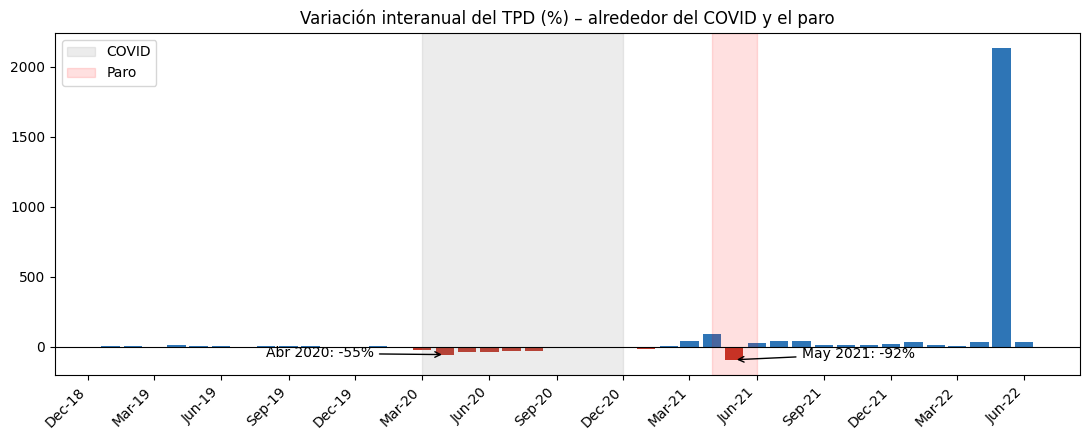

In [ ]:
import matplotlib.dates as mdates

v = m.loc["2019-01":"2022-06"]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(v.index, v["yoy_tpd"], width=25, color=np.where(v["yoy_tpd"] >= 0, "#2e75b6", "#c0392b"))
ax.axhline(0, color="black", lw=.8)
ax.axvspan(pd.Timestamp(COVID[0]), pd.Timestamp(COVID[1]), color="grey", alpha=.15, label="COVID")
ax.axvspan(pd.Timestamp(PARO[0]), pd.Timestamp(PARO[1]), color="red", alpha=.12, label="Paro")
ax.annotate("Abr 2020: -55%", xy=(pd.Timestamp("2020-04-01"), -55), xytext=(pd.Timestamp("2019-08-01"), -75),
            arrowprops=dict(arrowstyle="->"))
ax.annotate("May 2021: -92%", xy=(pd.Timestamp("2021-05-01"), -92), xytext=(pd.Timestamp("2021-08-01"), -80),
            arrowprops=dict(arrowstyle="->"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_title("Variación interanual del TPD (%) – alrededor del COVID y el paro")
ax.legend(); plt.tight_layout(); plt.show()

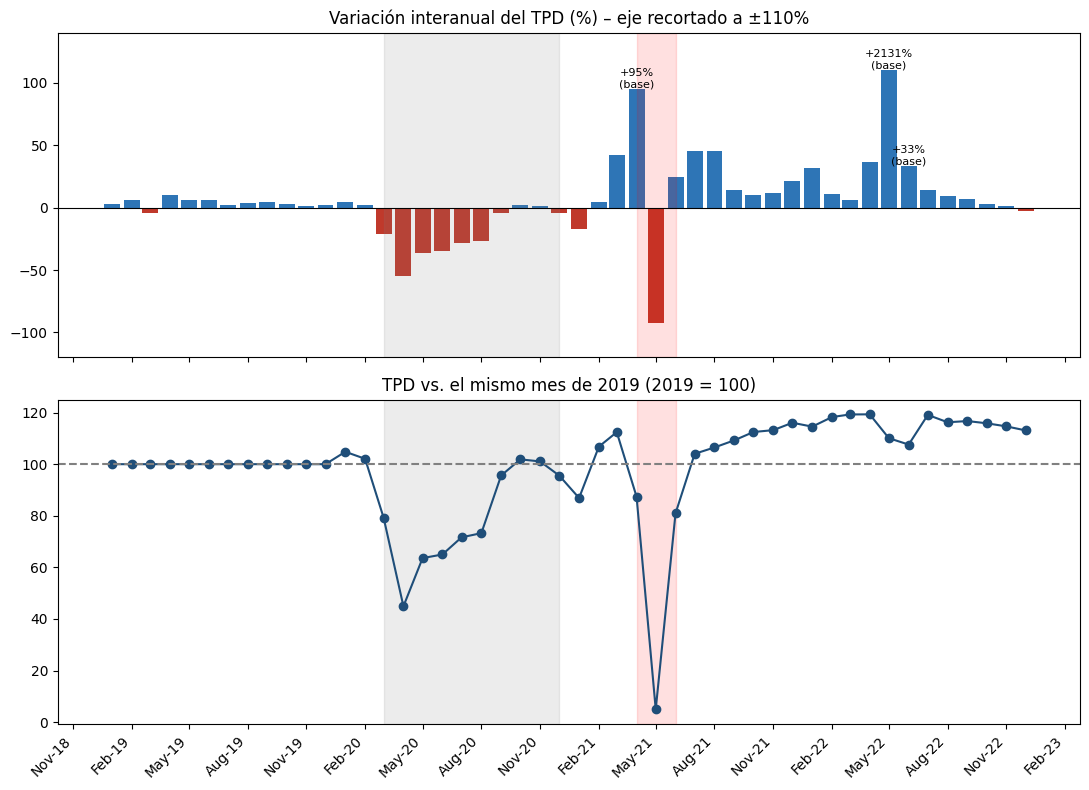

In [ ]:
import matplotlib.dates as mdates

v = m.loc["2019-01":"2022-12"].copy()
base2019 = m.loc["2019"].set_index(m.loc["2019"].index.month)["tpd"]
v["idx_vs_2019"] = v["tpd"] / v.index.month.map(base2019).values * 100

fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
ax[0].bar(v.index, v["yoy_tpd"].clip(-110, 110), width=25, color=np.where(v["yoy_tpd"] >= 0, "#2e75b6", "#c0392b"))
ax[0].axhline(0, color="black", lw=.8)
for f, txt in [("2021-04-01", "+95%\n(base)"), ("2022-05-01", "+2131%\n(base)"), ("2022-06-01", "+33%\n(base)")]:
    ax[0].annotate(txt, (pd.Timestamp(f), min(v.loc[f, "yoy_tpd"], 110)), ha="center", va="bottom", fontsize=8)
ax[0].set_ylim(-120, 140); ax[0].set_title("Variación interanual del TPD (%) – eje recortado a ±110%")

ax[1].plot(v.index, v["idx_vs_2019"], marker="o", color="#1f4e79")
ax[1].axhline(100, color="grey", ls="--"); ax[1].set_title("TPD vs. el mismo mes de 2019 (2019 = 100)")

for a in ax:
    a.axvspan(pd.Timestamp(COVID[0]), pd.Timestamp(COVID[1]), color="grey", alpha=.15)
    a.axvspan(pd.Timestamp(PARO[0]), pd.Timestamp(PARO[1]), color="red", alpha=.12)
ax[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
plt.setp(ax[1].get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()

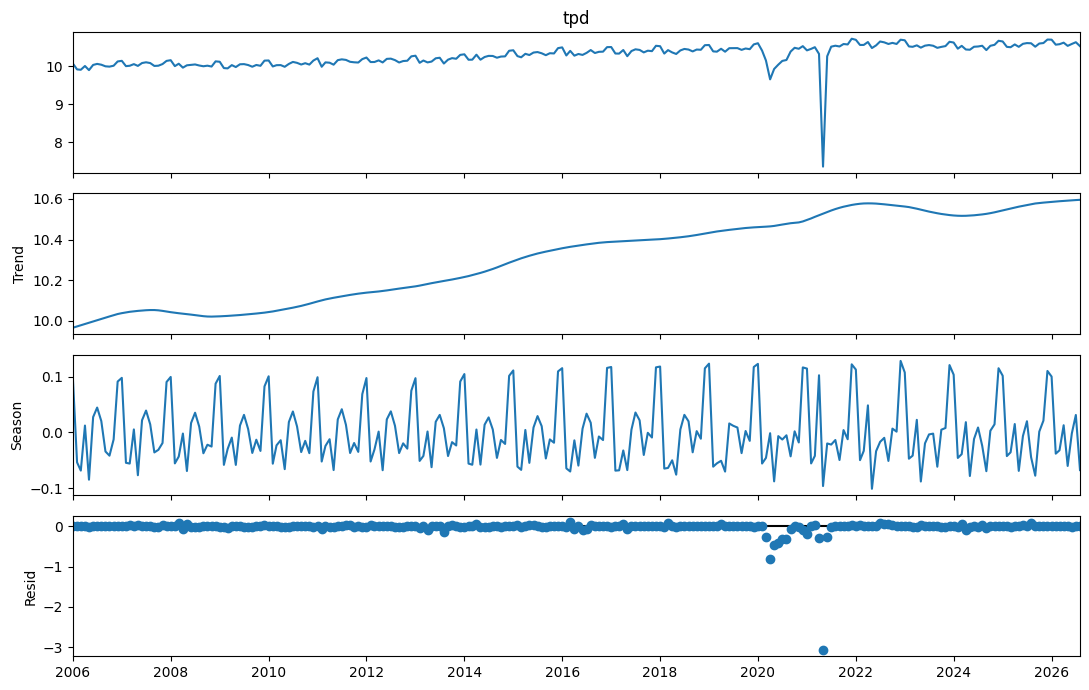

Meses atípicos: ['2020-04', '2021-05']


In [ ]:
# ===== 2. Descomposición STL =====
if HAS_SM:
    stl = STL(np.log(m.loc["2006":, "tpd"]), period=12, robust=True).fit()
    fig = stl.plot(); fig.set_size_inches(11, 7); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/fig_stl.png", dpi=130); plt.show()
    res = stl.resid
    atip = res[abs(res) > 2.5 * res.std()]
    print("Meses atípicos:", [d.strftime("%Y-%m") for d in atip.index])
else:
    print("STL omitida (statsmodels no disponible).")

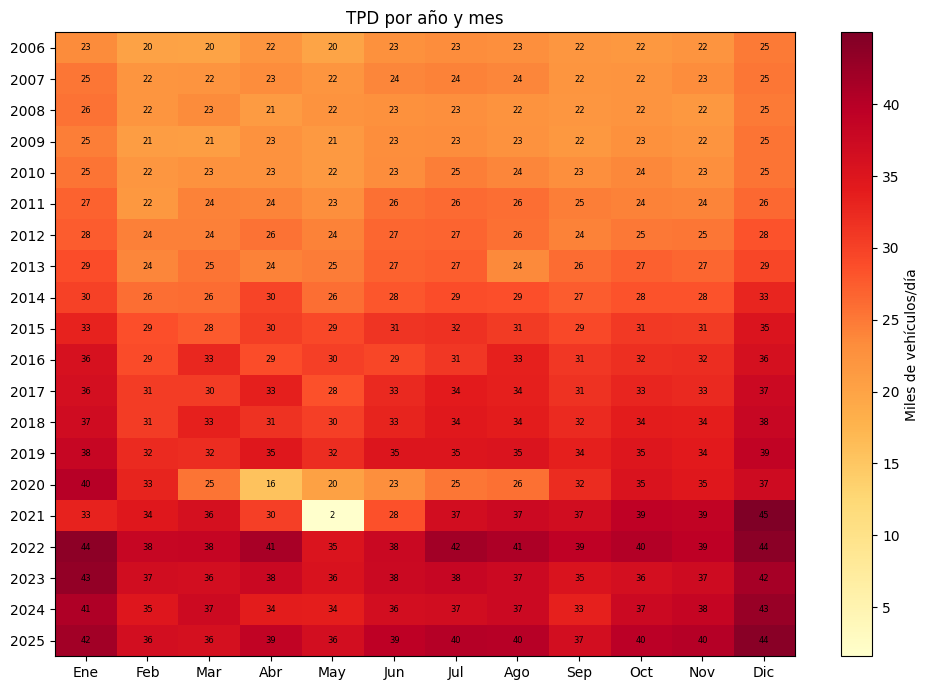

In [ ]:
# ===== 3. Mapa de calor año × mes =====
hm = (m.loc["2006":"2025"]
        .assign(anio=lambda x: x.index.year, mes=lambda x: x.index.month)
        .pivot(index="anio", columns="mes", values="tpd") / 1e3)
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(hm.values, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(12)); ax.set_xticklabels(["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"])
ax.set_yticks(range(len(hm))); ax.set_yticklabels(hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        ax.text(j, i, f"{hm.values[i, j]:.0f}", ha="center", va="center", fontsize=6)
plt.colorbar(im, label="Miles de vehículos/día"); ax.set_title("TPD por año y mes")
plt.tight_layout(); plt.show()

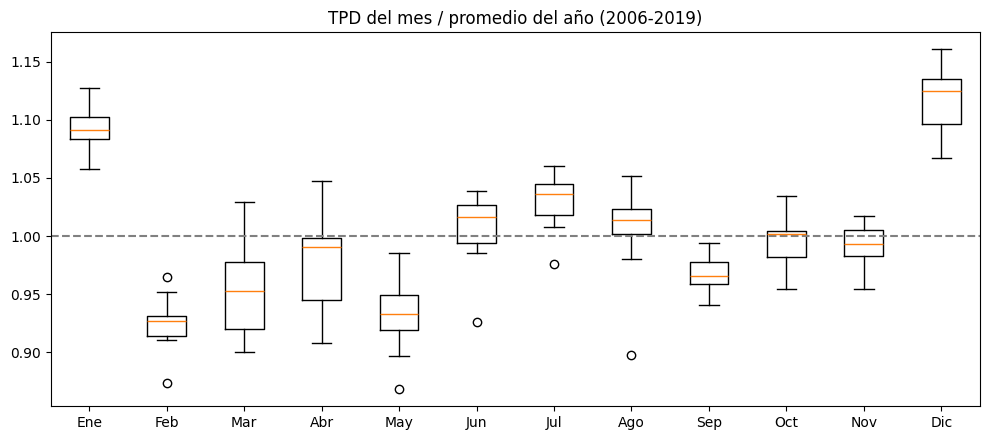

In [ ]:
# ===== 4. Estacionalidad (2006-2019) =====
z = m.loc["2006":"2019", "tpd"]
rel = z / z.groupby(z.index.year).transform("mean")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([rel[rel.index.month == k] for k in range(1, 13)])
ax.set_xticklabels(["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"])
ax.axhline(1, color="grey", ls="--"); ax.set_title("TPD del mes / promedio del año (2006-2019)")
plt.tight_layout(); plt.show()

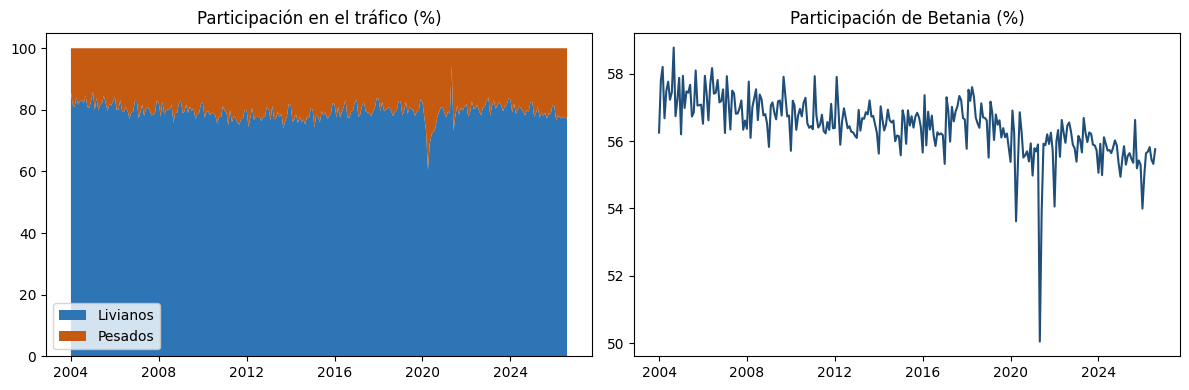

In [ ]:
# ===== 5. Composición del tráfico =====
share = m[["trafico_livianos", "trafico_pesados"]].div(m["trafico_total"], axis=0) * 100
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].stackplot(share.index, share["trafico_livianos"], share["trafico_pesados"],
                labels=["Livianos", "Pesados"], colors=["#2e75b6", "#c55a11"])
ax[0].set_title("Participación en el tráfico (%)"); ax[0].legend(loc="lower left")
ax[1].plot(m.index, m["trafico_betania"] / m["trafico_total"] * 100, color="#1f4e79")
ax[1].set_title("Participación de Betania (%)")
plt.tight_layout(); plt.show()

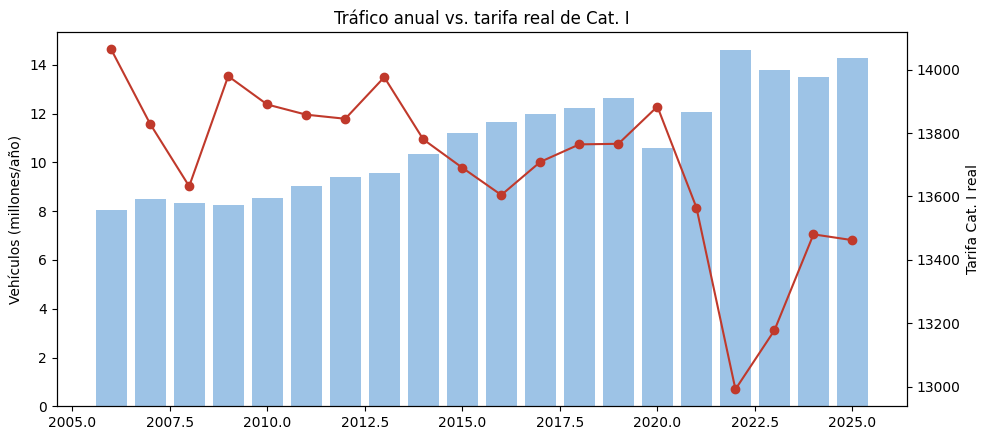

Correlación de variaciones anuales: -0.71


In [ ]:
# ===== 6. Tarifa real vs. tráfico anual =====
a = m.loc["2006":"2025"]
anual = a.groupby(a.index.year).agg(trafico=("trafico_total", "sum"),
                                     tarifa_real=("tarifa_cat1_real", "mean"),
                                     ingreso=("ingreso_teorico", "sum"))
fig, ax = plt.subplots(figsize=(10, 4.5)); ax2 = ax.twinx()
ax.bar(anual.index, anual["trafico"] / 1e6, color="#9dc3e6"); ax.set_ylabel("Vehículos (millones/año)")
ax2.plot(anual.index, anual["tarifa_real"], color="#c0392b", marker="o"); ax2.set_ylabel("Tarifa Cat. I real")
ax.set_title("Tráfico anual vs. tarifa real de Cat. I"); plt.tight_layout(); plt.show()
print("Correlación de variaciones anuales:", round(np.log(anual).diff()[["trafico", "tarifa_real"]].corr().iloc[0, 1], 2))

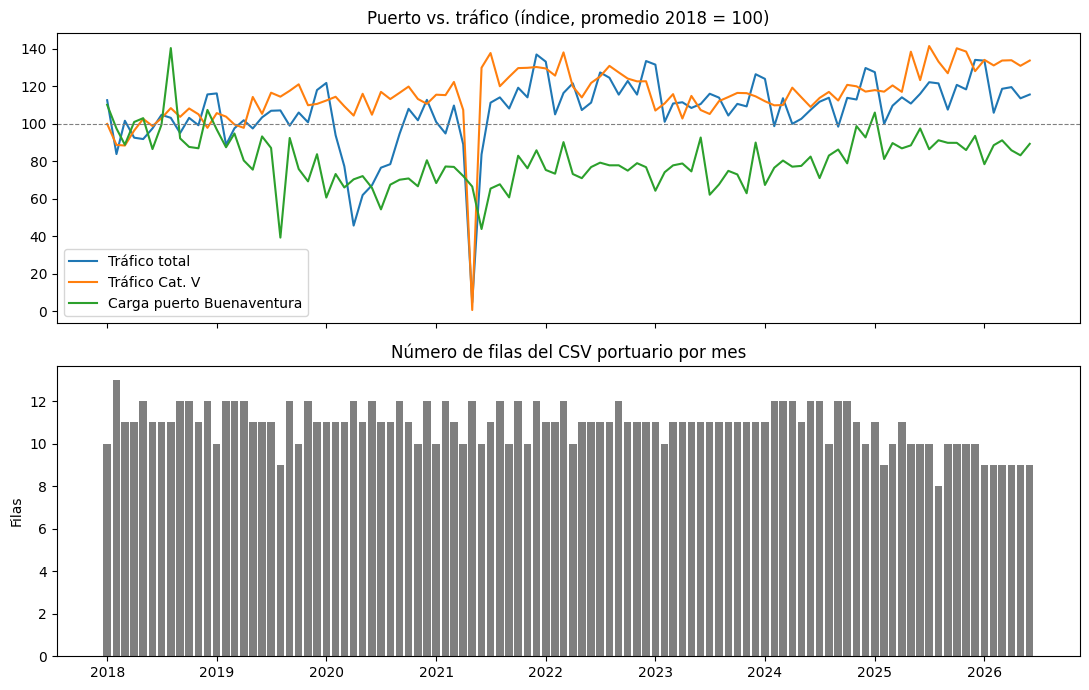

In [ ]:
p = m.dropna(subset=["port_total"])[["trafico_total", "trafico_cat5", "port_total", "port_registros"]]
cols = ["trafico_total", "trafico_cat5", "port_total"]
nombres = {"trafico_total": "Tráfico total", "trafico_cat5": "Tráfico Cat. V",
           "port_total": "Carga puerto Buenaventura"}
idx100 = p[cols].div(p[cols].iloc[:12].mean()) * 100

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for c in cols:
    ax[0].plot(idx100.index, idx100[c], label=nombres[c])
ax[0].axhline(100, color="grey", ls="--", lw=.8)
ax[0].set_title("Puerto vs. tráfico (índice, promedio 2018 = 100)"); ax[0].legend()
ax[1].bar(p.index, p["port_registros"], width=25, color="#7f7f7f")
ax[1].set_title("Número de filas del CSV portuario por mes"); ax[1].set_ylabel("Filas")
plt.tight_layout(); plt.show()

In [ ]:
# ¿Aporta información el puerto? Correlación de variaciones interanuales (log) con rezagos
ex = m.dropna(subset=["port_total"]).copy()
ex = ex[ex["port_registros"] > 0]
v = np.log(ex[["trafico_total", "trafico_pesados", "trafico_cat5", "port_total", "port_contenedores"]]).diff(12).dropna()
tabla = pd.DataFrame({f"rezago {L}m": {
    "tráfico total ~ puerto": v["trafico_total"].corr(v["port_total"].shift(L)),
    "pesados ~ puerto": v["trafico_pesados"].corr(v["port_total"].shift(L)),
    "Cat. V ~ puerto": v["trafico_cat5"].corr(v["port_total"].shift(L)),
    "Cat. V ~ contenedores": v["trafico_cat5"].corr(v["port_contenedores"].shift(L)),
} for L in range(0, 4)}).round(2)
print("Correlación de variaciones anuales (n =", len(v), "meses)")
print(tabla)

Correlación de variaciones anuales (n = 90 meses)
                        rezago 0m  rezago 1m  rezago 2m  rezago 3m
tráfico total ~ puerto       0.11       0.10       0.09       0.08
pesados ~ puerto             0.07       0.01       0.03      -0.02
Cat. V ~ puerto              0.05      -0.01      -0.00      -0.03
Cat. V ~ contenedores       -0.02      -0.08      -0.01      -0.04


In [ ]:
d_ = m.loc["2006":].copy()
d_["tpd_pesados"] = d_["trafico_pesados"] / d_["dias"]
d_["tpd_cat5"] = d_["trafico_cat5"] / d_["dias"]
MASCARAS = {"Toda la muestra 2006-2026": np.ones(len(d_), bool),
            "Sin COVID/paro (excl. mar-2020 a dic-2021)": ((d_.index < "2020-03-01") | (d_.index > "2021-12-01")),
            "Solo 2006-2019": (d_.index < "2020-01-01")}
VARS_ISE = {"ISE total (original)": "ise", "ISE total (desest.)": "ise_sa",
            "ISE comercio-transporte": "ise_comercio_transp", "ISE industria-construcción": "ise_industria"}
OBJ = {"TPD total": "tpd", "TPD pesados": "tpd_pesados", "TPD Cat. V": "tpd_cat5"}

filas_corr = []
for nom_m, mask in MASCARAS.items():
    for nom_o, col_o in OBJ.items():
        y_ = np.log(d_[col_o]).diff(12)
        for nom_v, col_v in VARS_ISE.items():
            x_ = np.log(d_[col_v]).diff(12)
            for L in (0, 1, 2, 3, 6):
                z_ = pd.concat([y_, x_.shift(L)], axis=1)[mask].dropna()
                filas_corr.append((nom_m, nom_o, nom_v, L, z_.iloc[:, 0].corr(z_.iloc[:, 1]), len(z_)))
corr_ise = pd.DataFrame(filas_corr, columns=["muestra", "objetivo", "variable", "rezago_m", "corr", "n"])
corr_ise.to_csv(f"{OUT_DIR}/corr_ise_trafico.csv", index=False)

for nom_m in MASCARAS:
    t_ = corr_ise[(corr_ise["muestra"] == nom_m) & (corr_ise["objetivo"] == "TPD total")]
    print(f"\n{nom_m}  (correlación de variaciones anuales con TPD total)")
    print(t_.pivot(index="variable", columns="rezago_m", values="corr").round(2).to_string())


Toda la muestra 2006-2026  (correlación de variaciones anuales con TPD total)
rezago_m                       0     1     2     3     6
variable                                                
ISE comercio-transporte     0.35  0.19  0.17  0.24  0.13
ISE industria-construcción  0.40  0.04  0.12  0.23  0.13
ISE total (desest.)         0.37  0.15  0.17  0.24  0.17
ISE total (original)        0.36  0.16  0.15  0.25  0.16

Sin COVID/paro (excl. mar-2020 a dic-2021)  (correlación de variaciones anuales con TPD total)
rezago_m                       0     1     2     3     6
variable                                                
ISE comercio-transporte     0.53  0.45  0.27  0.22  0.27
ISE industria-construcción  0.44  0.24  0.13  0.15  0.14
ISE total (desest.)         0.47  0.31  0.21  0.19  0.26
ISE total (original)        0.43  0.32  0.19  0.18  0.25

Solo 2006-2019  (correlación de variaciones anuales con TPD total)
rezago_m                       0     1     2     3     6
variable        

###3.4 Análisis de correlación con el ISE

Se comparan variaciones anuales (log) del tráfico contra variaciones anuales del ISE con rezagos de 0 a 6 meses. Para evitar que el COVID y el paro dominen la correlación, se reporta (a) toda la muestra, (b) excluyendo marzo-2020 a diciembre-2021 y (c) solo 2006-2019.

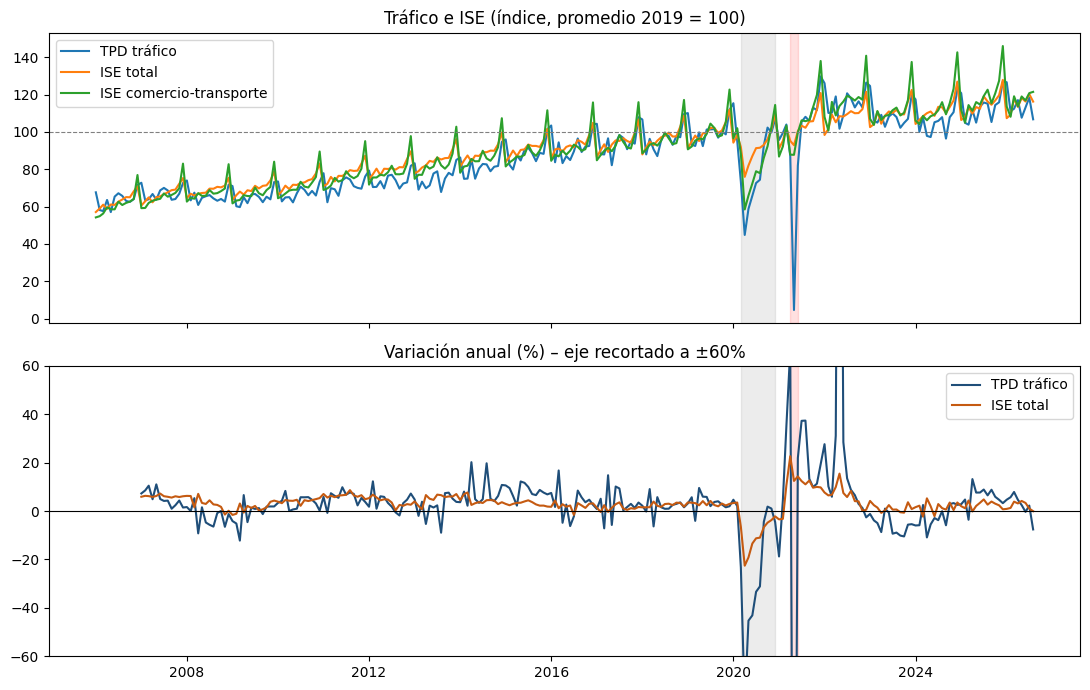

In [ ]:
z = m.loc["2006":, ["tpd", "ise", "ise_comercio_transp"]].dropna()
base = z.loc["2019"].mean()
yo = np.log(z).diff(12) * 100
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for c, nom in [("tpd", "TPD tráfico"), ("ise", "ISE total"), ("ise_comercio_transp", "ISE comercio-transporte")]:
    ax[0].plot(z.index, z[c] / base[c] * 100, label=nom)
ax[0].axhline(100, color="grey", ls="--", lw=.8); ax[0].legend(); ax[0].set_title("Tráfico e ISE (índice, promedio 2019 = 100)")
ax[1].plot(yo.index, yo["tpd"], label="TPD tráfico", color="#1f4e79")
ax[1].plot(yo.index, yo["ise"], label="ISE total", color="#c55a11")
ax[1].set_ylim(-60, 60); ax[1].axhline(0, color="black", lw=.8); ax[1].legend()
ax[1].set_title("Variación anual (%) – eje recortado a ±60%")
for a in ax:
    a.axvspan(pd.Timestamp(COVID[0]), pd.Timestamp(COVID[1]), color="grey", alpha=.15)
    a.axvspan(pd.Timestamp(PARO[0]), pd.Timestamp(PARO[1]), color="red", alpha=.12)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_ise_vs_trafico.png", dpi=130); plt.show()

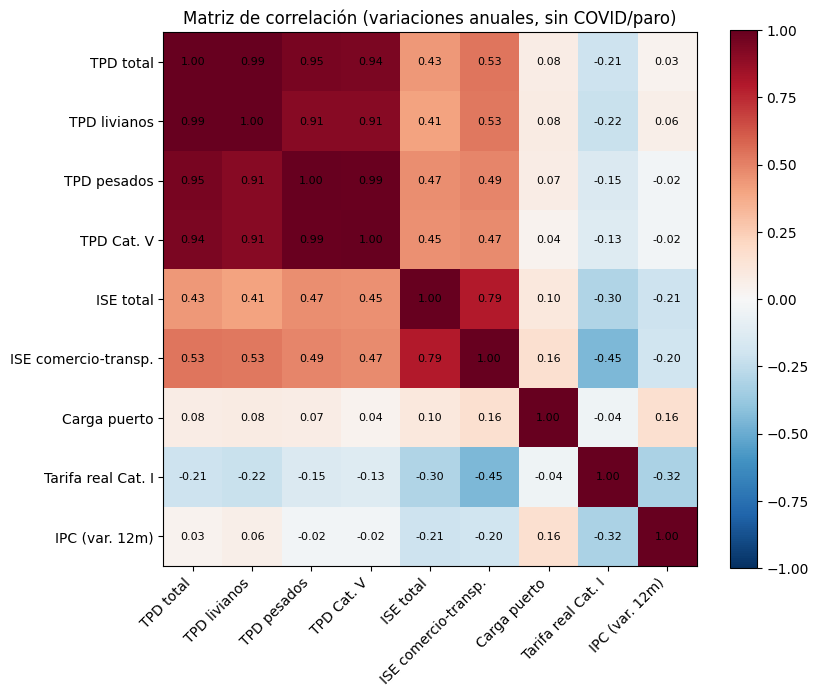

In [ ]:
mm = m.loc["2006":].copy()
mm["tarifa_real_yoy"] = np.log(mm["tarifa_cat1_real"]).diff(12)
yo = pd.DataFrame({
    "TPD total": np.log(mm["tpd"]).diff(12),
    "TPD livianos": np.log(mm["trafico_livianos"] / mm["dias"]).diff(12),
    "TPD pesados": np.log(mm["trafico_pesados"] / mm["dias"]).diff(12),
    "TPD Cat. V": np.log(mm["trafico_cat5"] / mm["dias"]).diff(12),
    "ISE total": np.log(mm["ise"]).diff(12),
    "ISE comercio-transp.": np.log(mm["ise_comercio_transp"]).diff(12),
    "Carga puerto": np.log(mm["port_total"]).diff(12),
    "Tarifa real Cat. I": mm["tarifa_real_yoy"],
    "IPC (var. 12m)": mm["ipc_var12"],
})
fuera = ~(((mm.index >= "2020-03-01") & (mm.index <= "2021-12-01")))
cm = yo[fuera].corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(cm.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=45, ha="right")
ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.columns)
for i in range(len(cm)):
    for j in range(len(cm)):
        ax.text(j, i, f"{cm.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im); ax.set_title("Matriz de correlación (variaciones anuales, sin COVID/paro)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_matriz_correlacion.png", dpi=130); plt.show()
cm.round(2).to_csv(f"{OUT_DIR}/matriz_correlacion.csv")

### 3.5 Definición de la variable objetivo, del horizonte y partición temporal
**Estrategia de pronóstico directo a 12 meses.** Para cada fecha de corte *t* y cada horizonte *h* = 1…12 se predice el **crecimiento interanual del TMD** (log TPD(t+h) − log TPD(t+h−12)) con información disponible hasta *t*. Así el modelo ya queda "desestacionalizado" y sin tendencia, y se evita acumular errores recursivos.

Conjuntos de variables (ablación para medir qué aporta cada bloque):
- **A_base**: crecimiento reciente (1, 3, 6, 12 m), mes, calendario (festivos, fines de semana, Semana Santa), COVID/paro.
- **B_macro**: A + IPC (var. 12m) y variación real de la tarifa Cat. I.
- **C_puerto**: B + variación interanual (media 3 meses) de la carga del puerto de Buenaventura, con 2 meses de rezago de publicación.
- **D_ise**: B + variación interanual (media 3 meses) del **ISE total**, con 2 meses de rezago de publicación.
- **E_ise_sector**: B + variación interanual (media 3 meses) del **ISE de comercio-transporte**, con 2 meses de rezago.

In [ ]:
try:
    import sklearn.tree._criterion
except Exception:
    pass
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

H = 12                  # horizonte (meses)
LAG_PUERTO = 2          # meses de rezago con que se conoce el dato portuario
LAG_ISE = 2             # el DANE publica el ISE ~7 semanas después del cierre del mes → 2 meses de rezago
SEED = 42

d = m.loc[VENTANA_INICIO:].copy()
N = len(d)
y = np.log(d["tpd"].values)                                   # variable que se modela: log(TMD)

idx_ext = pd.date_range(d.index[0], periods=N + H + 6, freq="MS")   # calendario también hacia el futuro
cal = calendario(idx_ext).join(eventos(idx_ext))
fest, findes, ss, cov, paro, dias = (cal[c].values for c in
                                     ["n_festivos", "n_findes", "semana_santa", "covid", "paro", "dias"])
mes = cal.index.month.values
ipc12 = d["ipc_var12"].values
tar_real = d["tarifa_cat1_real"].values
port_tot = d["port_total"].values                            # NaN antes de 2018 y después de jun-2026
ise_v = d["ise"].values
ise_ct = d["ise_comercio_transp"].values

def construir_filas():
    filas = []
    for t in range(23, N):
        g = {"g1": y[t] - y[t - 12]}
        for k in (3, 6, 12):
            g[f"g{k}"] = y[t - k + 1:t + 1].mean() - y[t - 12 - k + 1:t - 12 + 1].mean()
        g["ipc_var12"] = ipc12[t]
        g["tarifa_real_yoy"] = np.log(tar_real[t] / tar_real[t - 12])
        tp = t - LAG_PUERTO
        a, b0 = port_tot[tp - 2:tp + 1].mean(), port_tot[tp - 14:tp - 11].mean()
        g["port_yoy3"] = np.log(a / b0) if (a > 0 and b0 > 0) else np.nan
        ti = t - LAG_ISE
        g["ise_yoy3"] = np.log(ise_v[ti - 2:ti + 1].mean() / ise_v[ti - 14:ti - 11].mean())
        g["ise_ct_yoy3"] = np.log(ise_ct[ti - 2:ti + 1].mean() / ise_ct[ti - 14:ti - 11].mean())
        for h in range(1, H + 1):
            s, b = t + h, t + h - 12
            f = dict(t=t, h=h, s=s, y_base=y[b], **g,
                     d_fest=fest[s] - fest[b], d_findes=findes[s] - findes[b], d_ss=ss[s] - ss[b],
                     tgt_covid=cov[s], tgt_paro=paro[s], base_covid=cov[b], base_paro=paro[b])
            for k in range(2, 13):
                f[f"mes{k}"] = int(mes[s] == k)
            f["z"] = y[s] - y[b] if s < N else np.nan
            filas.append(f)
    return pd.DataFrame(filas)

filas = construir_filas()
BASE = ["g1", "g3", "g6", "g12", "h", "d_fest", "d_findes", "d_ss", "tgt_covid", "tgt_paro",
        "base_covid", "base_paro"] + [f"mes{k}" for k in range(2, 13)]
SETS = {"A_base": BASE,
        "B_macro": BASE + ["ipc_var12", "tarifa_real_yoy"],
        "C_puerto": BASE + ["ipc_var12", "tarifa_real_yoy", "port_yoy3"],
        "D_ise": BASE + ["ipc_var12", "tarifa_real_yoy", "ise_yoy3"],
        "E_ise_sector": BASE + ["ipc_var12", "tarifa_real_yoy", "ise_ct_yoy3"]}
print("Filas (corte × horizonte):", len(filas), "| meses en la ventana:", N)

Filas (corte × horizonte): 2700 | meses en la ventana: 248


## FASE 4 · Modelado  *(Objetivo específico 2)*
- **Referencia:** naive estacional (mismo mes del año anterior) y naive + crecimiento de los últimos 12 meses.
- **Estadísticos:** SARIMAX (con festivos, Semana Santa, COVID y paro como exógenas) y Holt-Winters (ETS).
- **Machine learning (pronóstico directo):** Regresión Ridge (lineal), Random Forest, Gradient Boosting y red neuronal (MLP).


In [ ]:
def modelos_ml():
    return {
        "Ridge": lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))),
        "RandomForest": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
        "GradBoost": lambda: GradientBoostingRegressor(n_estimators=300, learning_rate=0.03, max_depth=3,
                                                       subsample=0.8, random_state=SEED),
        "MLP": lambda: make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(32, 16), alpha=1e-2,
                                                                    max_iter=3000, random_state=SEED)),
    }

def pred_ml(fabrica, cols, T, exigir=()):
    # 'exigir': columnas que deben existir en el entrenamiento aunque no se usen como variables
    # (sirve para comparar con/sin puerto sobre exactamente la misma muestra)
    tr_ = filas[filas["s"] <= T].dropna(subset=cols + list(exigir) + ["z"])
    te_ = filas[filas["t"] == T].sort_values("h")
    if te_[cols].isna().any().any():
        return None
    mod = fabrica()
    mod.fit(tr_[cols].values, tr_["z"].values)
    return te_["y_base"].values + mod.predict(te_[cols].values)       # log TMD para T+1..T+12

def pred_naive(T):
    return np.array([y[T + h - 12] for h in range(1, H + 1)])

def pred_naive_g(T):
    g = y[T - 11:T + 1].mean() - y[T - 23:T - 11].mean()
    return pred_naive(T) + g

EXOG = np.column_stack([fest, findes, ss, cov, paro]).astype(float)

if HAS_SM:                                                               # >>> MODIFICADO: guarda statsmodels
    def pred_sarimax(T, order, sorder):
        res = SARIMAX(y[:T + 1], exog=EXOG[:T + 1], order=order, seasonal_order=sorder,
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
        return res.forecast(H, exog=EXOG[T + 1:T + 1 + H])

    def pred_sarima_clasico(T):
        # Especificación fija a priori (no ajustada con los datos de prueba): SARIMA(1,1,1)(0,1,1)12 sin exógenas
        res = SARIMAX(y[:T + 1], order=(1, 1, 1), seasonal_order=(0, 1, 1, 12),
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
        return res.forecast(H)

    def pred_ets(T):
        res = ExponentialSmoothing(y[:T + 1], trend="add", damped_trend=True, seasonal="add",
                                   seasonal_periods=12).fit()
        return res.forecast(H)

# Fechas de corte del backtesting: cada 3 meses, el último con 12 meses completos de real para comparar
ORIGENES = [N - 1 - H - 3 * k for k in range(12)][::-1]
print("Cortes de validación:", d.index[ORIGENES[0]].date(), "→", d.index[ORIGENES[-1]].date(), f"({len(ORIGENES)} cortes × {H} horizontes)")

Cortes de validación: 2022-11-01 → 2025-08-01 (12 cortes × 12 horizontes)


### 4.1 Selección del orden SARIMAX (AIC en el primer corte; se mantiene fijo en el resto)

In [ ]:
if HAS_SM:
    T0 = ORIGENES[0]
    t0 = time.time()
    cand = []
    for p, q, dd, P, Q in itertools.product([0, 1, 2], [0, 1], [0, 1], [0, 1], [0, 1]):
        try:
            r = SARIMAX(y[:T0 + 1], exog=EXOG[:T0 + 1], order=(p, dd, q), seasonal_order=(P, 1, Q, 12),
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
            cand.append(((p, dd, q), (P, 1, Q, 12), r.aic))
        except Exception:
            pass
    cand = sorted(cand, key=lambda c: c[2])
    ORD, SORD, _ = cand[0]
    print("Mejores órdenes por AIC:"); [print("  ", c) for c in cand[:3]]
    print(f"→ SARIMAX{ORD}x{SORD}  ({time.time() - t0:.0f}s)")
else:
    print("SARIMAX omitido (statsmodels no disponible).")

Mejores órdenes por AIC:
   ((2, 1, 1), (1, 1, 1, 12), np.float64(-118.54415924823059))
   ((2, 1, 1), (0, 1, 1, 12), np.float64(-116.72187705034634))
   ((1, 1, 1), (1, 1, 1, 12), np.float64(-115.034040488226))
→ SARIMAX(2, 1, 1)x(1, 1, 1, 12)  (48s)


### 4.2 Entrenamiento con origen móvil (backtesting)
Para cada corte se entrena **solo con datos hasta ese mes** y se pronostican los 12 meses siguientes. Métricas sobre el **tráfico mensual total** (vehículos): MAE, RMSE y MAPE.

In [ ]:
MODELOS = {"Naive estacional": pred_naive, "Naive + crecimiento 12m": pred_naive_g}
if HAS_SM:                                                               # >>> MODIFICADO
    MODELOS.update({"SARIMA clásico (1,1,1)(0,1,1)12": pred_sarima_clasico,
                    "SARIMAX (orden por AIC + exógenas)": lambda T: pred_sarimax(T, ORD, SORD),
                    "Holt-Winters (ETS)": pred_ets})
# Conjuntos de variables. "B_misma_muestra" = B_macro entrenado SOLO con las filas donde hay dato de puerto:
# es el control justo para C_puerto (mismo tamaño de muestra, con y sin la variable del puerto).
CONJUNTOS = {"A_base": (SETS["A_base"], ()), "B_macro": (SETS["B_macro"], ()),
             "B_misma_muestra": (SETS["B_macro"], ("port_yoy3",)), "C_puerto": (SETS["C_puerto"], ()),
             "D_ise": (SETS["D_ise"], ()), "E_ise_sector": (SETS["E_ise_sector"], ())}      # >>> NUEVO: D y E
for algo, fab in modelos_ml().items():
    for nombre_set, (cols, exig) in CONJUNTOS.items():
        MODELOS[f"{algo} [{nombre_set}]"] = (lambda fab, cols, exig: (lambda T: pred_ml(fab, cols, T, exig)))(fab, cols, exig)

registros = []
t0 = time.time()
for nombre, fn in MODELOS.items():
    for T in ORIGENES:
        yh = fn(T)
        if yh is None:
            continue
        pred = np.exp(yh) * dias[T + 1:T + 1 + H]
        real = d["trafico_total"].values[T + 1:T + 1 + H]
        for h in range(H):
            registros.append((nombre, d.index[T], h + 1, d.index[T + 1 + h], real[h], pred[h]))
    print(f"{nombre:<34s} listo  ({time.time() - t0:.0f}s acumulados)")

bt = pd.DataFrame(registros, columns=["modelo", "corte", "h", "fecha", "real", "pred"])

Naive estacional                   listo  (0s acumulados)
Naive + crecimiento 12m            listo  (0s acumulados)
SARIMA clásico (1,1,1)(0,1,1)12    listo  (5s acumulados)
SARIMAX (orden por AIC + exógenas) listo  (40s acumulados)
Holt-Winters (ETS)                 listo  (42s acumulados)
Ridge [A_base]                     listo  (42s acumulados)
Ridge [B_macro]                    listo  (42s acumulados)
Ridge [B_misma_muestra]            listo  (42s acumulados)
Ridge [C_puerto]                   listo  (42s acumulados)
Ridge [D_ise]                      listo  (42s acumulados)
Ridge [E_ise_sector]               listo  (42s acumulados)
RandomForest [A_base]              listo  (70s acumulados)
RandomForest [B_macro]             listo  (101s acumulados)
RandomForest [B_misma_muestra]     listo  (110s acumulados)
RandomForest [C_puerto]            listo  (120s acumulados)
RandomForest [D_ise]               listo  (153s acumulados)
RandomForest [E_ise_sector]        listo  (186s acumula

## FASE 5 · Evaluación y resultados


### 5.1 Selección del ensamble sin sesgo optimista

In [ ]:
def mape(g): return (abs(g["pred"] - g["real"]) / g["real"]).mean() * 100

ult_sel = d.index[ORIGENES[5] + H]            # >>> NUEVO: último mes objetivo de la ventana de selección
print("Ventana de selección: metas hasta", ult_sel.date(), "| validación (holdout): metas desde",
      (ult_sel + pd.offsets.MonthBegin(1)).date(), "hasta", d.index[-1].date())

cand_ens = [n for n in bt["modelo"].unique() if "misma_muestra" not in n]
rank_sel = (bt[(bt["fecha"] <= ult_sel) & bt["modelo"].isin(cand_ens)]
            .groupby("modelo").apply(mape).sort_values())
top3 = rank_sel.index[:3].tolist()
print("Top-3 elegidos SOLO con la ventana de selección:", top3)

ens = bt[bt["modelo"].isin(top3)].groupby(["corte", "h", "fecha", "real"], as_index=False)["pred"].mean()
ens["modelo"] = "Ensamble top-3"
bt = pd.concat([bt, ens[bt.columns]], ignore_index=True)

bt["err"] = bt["pred"] - bt["real"]
bt["ape"] = bt["err"].abs() / bt["real"]
def resumen(g):
    return pd.Series({
        "MAE": g["err"].abs().mean(), "RMSE": np.sqrt((g["err"] ** 2).mean()), "MAPE_%": g["ape"].mean() * 100,
        "MAPE_h1-3_%": g.loc[g["h"] <= 3, "ape"].mean() * 100,
        "MAPE_h4-6_%": g.loc[g["h"].between(4, 6), "ape"].mean() * 100,
        "MAPE_h7-12_%": g.loc[g["h"] >= 7, "ape"].mean() * 100})

Ventana de selección: metas hasta 2025-02-01 | validación (holdout): metas desde 2025-03-01 hasta 2026-08-01
Top-3 elegidos SOLO con la ventana de selección: ['Ridge [E_ise_sector]', 'Ridge [D_ise]', 'Ridge [B_macro]']


### 5.2 Métricas del backtesting completo y de la ventana de validación (holdout)

In [ ]:
metricas = bt.groupby("modelo").apply(resumen).sort_values("MAPE_%").round(2)
metricas.to_csv(f"{OUT_DIR}/metricas_modelos.csv")
print("=== Backtesting completo (12 cortes × 12 horizontes) ===")
print(metricas.to_string())

hold = bt[bt["fecha"] > ult_sel]                                        # >>> NUEVO
metricas_hold = hold.groupby("modelo").apply(resumen).sort_values("MAPE_%").round(2)
n_naive = metricas_hold.loc["Naive estacional", "MAPE_%"]
metricas_hold["MAPE_vs_naive"] = (metricas_hold["MAPE_%"] / n_naive).round(2)
metricas_hold.to_csv(f"{OUT_DIR}/metricas_holdout.csv")        # >>> MODIFICADO: se guarda después de agregar MAPE_vs_naive
print(f"\n=== Ventana de validación (holdout): {hold['fecha'].min().date()} → {hold['fecha'].max().date()}, "
      f"{len(hold[hold['modelo'] == 'Naive estacional'])} pares corte-horizonte ===")
print(metricas_hold.to_string())
print("\nTop-3 usados en el ensamble:", top3)

=== Backtesting completo (12 cortes × 12 horizontes) ===
                                          MAE        RMSE  MAPE_%  MAPE_h1-3_%  MAPE_h4-6_%  MAPE_h7-12_%
modelo                                                                                                   
Ridge [E_ise_sector]                 51955.97    61670.24    4.52         4.45         4.35          4.64
Ensamble top-3                       52207.05    61994.04    4.54         4.46         4.37          4.66
Ridge [D_ise]                        52323.48    62143.87    4.55         4.47         4.38          4.68
Ridge [B_macro]                      52341.70    62174.30    4.55         4.47         4.38          4.68
RandomForest [E_ise_sector]          54903.03    70432.82    4.78         4.00         4.53          5.30
RandomForest [D_ise]                 55153.78    69668.18    4.80         3.78         4.52          5.46
GradBoost [D_ise]                    55197.92    70047.74    4.82         4.29         4.86    

### 5.3 Aporte de las variables externas: puerto e ISE (ablación). Se amplía con D_ise y E_ise_sector y se agrega una prueba pareada contra B_macro.

MAPE (%) según variables incluidas (backtesting completo):
set           A_base  B_macro  B_misma_muestra  C_puerto  D_ise  E_ise_sector
algoritmo                                                                    
GradBoost       5.10     4.83             8.39      8.37   4.82          4.86
MLP            11.10    10.66            41.90     28.91  10.13          9.94
RandomForest    5.36     4.95             7.70      7.79   4.80          4.78
Ridge           5.72     4.55            13.60     13.58   4.55          4.52

MAPE (%) según variables incluidas (solo ventana de validación):
set           A_base  B_macro  B_misma_muestra  C_puerto  D_ise  E_ise_sector
algoritmo                                                                    
GradBoost       3.12     3.88             5.92      5.86   3.93          3.90
MLP             3.25     5.67            12.94     16.43   6.84          6.19
RandomForest    3.77     3.90             5.45      5.56   3.93          3.77
Ridge           3

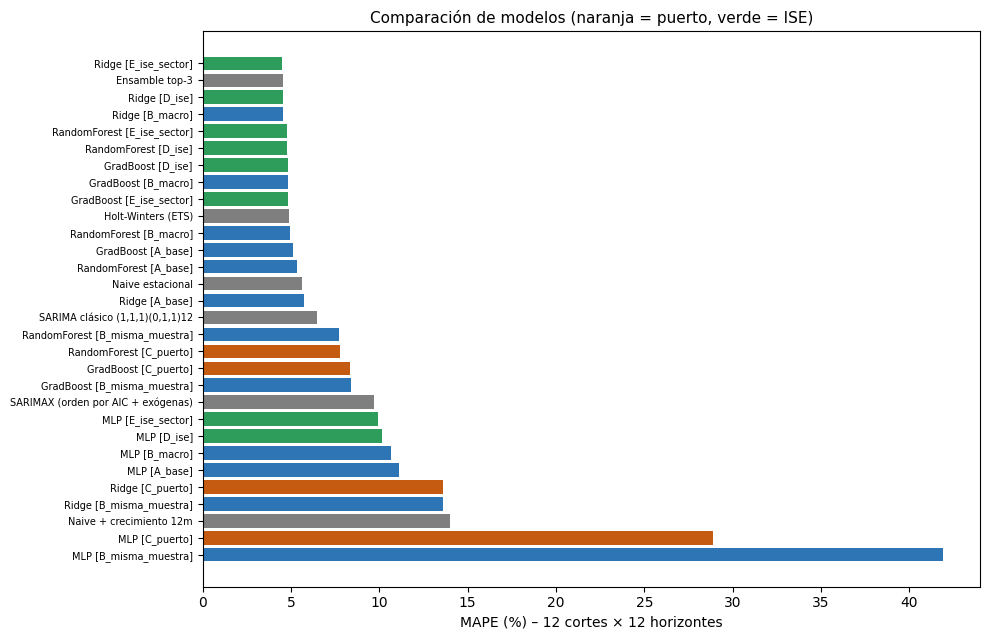

In [ ]:
abl = metricas.reset_index()
abl = abl[abl["modelo"].str.contains(r"\[")].copy()
abl["algoritmo"] = abl["modelo"].str.extract(r"^(.*?) \[")[0]
abl["set"] = abl["modelo"].str.extract(r"\[(.*)\]")[0]
orden_sets = ["A_base", "B_macro", "B_misma_muestra", "C_puerto", "D_ise", "E_ise_sector"]
tabla_abl = abl.pivot(index="algoritmo", columns="set", values="MAPE_%")[orden_sets]
print("MAPE (%) según variables incluidas (backtesting completo):")
print(tabla_abl.round(2))

abl_h = metricas_hold.reset_index()
abl_h = abl_h[abl_h["modelo"].str.contains(r"\[")].copy()
abl_h["algoritmo"] = abl_h["modelo"].str.extract(r"^(.*?) \[")[0]
abl_h["set"] = abl_h["modelo"].str.extract(r"\[(.*)\]")[0]
tabla_abl_h = abl_h.pivot(index="algoritmo", columns="set", values="MAPE_%")[orden_sets]
print("\nMAPE (%) según variables incluidas (solo ventana de validación):")
print(tabla_abl_h.round(2))

# prueba pareada (mismos corte × horizonte): ¿el modelo con ISE se equivoca menos que B_macro?
def comparar(a, b):
    xa = bt[bt["modelo"] == a].set_index(["corte", "h"])[["ape"]]
    xb = bt[bt["modelo"] == b].set_index(["corte", "h"])[["ape"]]
    j = xa.join(xb, lsuffix="_a", rsuffix="_b", how="inner")
    dif = (j["ape_a"] - j["ape_b"]) * 100
    return pd.Series({"n_pares": len(j), "dif_MAPE_pp": dif.mean(), "% pares donde mejora": (dif < 0).mean() * 100})
filas_c = []
for algo in modelos_ml():
    for s_ in ("C_puerto", "D_ise", "E_ise_sector"):
        r_ = comparar(f"{algo} [{s_}]", f"{algo} [B_macro]" if s_ != "C_puerto" else f"{algo} [B_misma_muestra]")
        filas_c.append(pd.concat([pd.Series({"algoritmo": algo, "comparación": f"{s_} vs " + ("B_misma_muestra" if s_ == "C_puerto" else "B_macro")}), r_]))
prueba_pareada = pd.DataFrame(filas_c).round(2)
print("\nPrueba pareada (dif_MAPE_pp < 0 = mejora al agregar la variable; los pares no son independientes, es indicativa):")
print(prueba_pareada.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6.5))
orden = metricas["MAPE_%"].sort_values(ascending=False)
colores = ["#c55a11" if "C_puerto" in n else "#2e9d5b" if ("D_ise" in n or "E_ise" in n) else "#2e75b6" if "[" in n else "#7f7f7f" for n in orden.index]
ax.barh(orden.index, orden.values, color=colores)
ax.set_xlabel("MAPE (%) – 12 cortes × 12 horizontes")
ax.set_title("Comparación de modelos (naranja = puerto, verde = ISE)", fontsize=11); ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig2_comparacion_modelos.png", dpi=130); plt.show()

## FASE 6 · Despliegue: pronóstico de tráfico y proyección de ingresos  *(Objetivo específico 3)*

### 6.1 Pronóstico a 12 meses con el modelo seleccionado.** El modelo final es el ensamble definido en 5.1 (configurable con `MODELO_FINAL`).

In [ ]:
MODELO_FINAL = "Ensamble top-3"        # >>> NUEVO: configurable (p. ej. "Ridge [B_macro]")
mejor = MODELO_FINAL
print("Modelo seleccionado:", mejor, "| componentes:", top3 if mejor == "Ensamble top-3" else "—")

def prediccion_final(nombre, T):
    if nombre == "Ensamble top-3":
        return np.mean([prediccion_final(n, T) for n in top3], axis=0)
    return MODELOS[nombre](T)

T = N - 1
yh = prediccion_final(mejor, T)
fechas = pd.date_range(d.index[-1] + pd.offsets.MonthBegin(1), periods=H, freq="MS")
fc = pd.DataFrame({"fecha": fechas, "trafico_pred": np.exp(yh) * dias[T + 1:T + 1 + H]})

# Intervalo empírico (P10-P90) a partir de los errores logarítmicos del backtesting del modelo elegido
b = bt[bt["modelo"] == mejor].copy()
b["le"] = np.log(b["real"] / b["pred"])
b["grupo"] = pd.cut(b["h"], [0, 4, 8, 12], labels=[0, 1, 2]).astype(int)
q = b.groupby("grupo")["le"].quantile([.1, .9]).unstack()
g = pd.cut(np.arange(1, H + 1), [0, 4, 8, 12], labels=[0, 1, 2]).astype(int)
fc["p10"] = fc["trafico_pred"] * np.exp(q.loc[g, 0.1].values)
fc["p90"] = fc["trafico_pred"] * np.exp(q.loc[g, 0.9].values)
hist12 = m.loc[d.index[-1] - pd.DateOffset(months=11):d.index[-1]]
print(f"Tráfico últimos 12 m reales: {hist12['trafico_total'].sum():,.0f} | pronóstico próximos 12 m: {fc['trafico_pred'].sum():,.0f} "
      f"({fc['trafico_pred'].sum() / hist12['trafico_total'].sum() - 1:+.1%})")
fc.round(0)

Modelo seleccionado: Ensamble top-3 | componentes: ['Ridge [E_ise_sector]', 'Ridge [D_ise]', 'Ridge [B_macro]']
Tráfico últimos 12 m reales: 14,518,001 | pronóstico próximos 12 m: 14,998,404 (+3.3%)


,fecha,trafico_pred,p10,p90
0,2026-09-01,1134375.0,1057143.0,1193436.0
1,2026-10-01,1250978.0,1165807.0,1316110.0
2,2026-11-01,1287148.0,1199514.0,1354163.0
3,2026-12-01,1417350.0,1320852.0,1491144.0
4,2027-01-01,1370869.0,1273350.0,1457064.0
5,2027-02-01,1111815.0,1032725.0,1181723.0
6,2027-03-01,1404430.0,1304524.0,1492736.0
7,2027-04-01,1137256.0,1056356.0,1208763.0
8,2027-05-01,1171749.0,1109192.0,1265547.0
9,2027-06-01,1206056.0,1141667.0,1302600.0


### 6.2 Ingresos por categoría, escenarios y sensibilidad

**Supuestos editables:** reajuste de tarifas el 1.º de enero = IPC 12 meses más reciente (redondeo a la centena, como en la propuesta); escenarios: tráfico P90/base/P10 y reajuste ± `DELTA_IPC` puntos.

In [ ]:
ANIO_ACTUAL = d.index[-1].year
tar_act = tf[tf["anio"] == ANIO_ACTUAL].set_index(["estacion", "categoria"])["tarifa"].fillna(0)

AJUSTE_TARIFA = None                      # p. ej. 0.05 para fijar 5 %
ajuste = AJUSTE_TARIFA if AJUSTE_TARIFA is not None else float(ipc["ipc_var12"].dropna().iloc[-1])
DELTA_IPC = 0.02                          # escenarios: reajuste base ± 2 puntos
print(f"Reajuste de tarifa base para {ANIO_ACTUAL + 1}: {ajuste:.1%}")

ult12 = tr[tr["fecha"] > d.index[-1] - pd.DateOffset(months=12)].copy()
ult12["mes"] = ult12["fecha"].dt.month
mix = ult12.groupby(["mes", "estacion", "categoria"])["vehiculos"].sum()
mix = mix / mix.groupby(level="mes").transform("sum")          # participación de cada (estación, categoría) en el mes

def grupo_cat(c):
    return "Ejes adicionales" if c.startswith("Eje") else c.replace(" E", "")    # 'Cat. I E' (exentos) se suma a 'Cat. I'

def tarifas_anio(anio, aj):
    return tar_act if anio == ANIO_ACTUAL else ((tar_act * (1 + aj) / 100).round() * 100)

def ingresos_detalle(trafico, fechas_, aj):
    filas_ = []
    for f, v in zip(fechas_, trafico):
        w = mix.xs(f.month, level="mes")
        tar = tarifas_anio(f.year, aj).reindex(w.index).fillna(0)
        ing = w * tar * v
        filas_.append(ing.groupby([grupo_cat(c) for c in ing.index.get_level_values("categoria")]).sum().rename(f))
    return pd.DataFrame(filas_).fillna(0)

ESC = {"Pesimista": ("p10", ajuste - DELTA_IPC), "Base": ("trafico_pred", ajuste), "Optimista": ("p90", ajuste + DELTA_IPC)}
det_esc, res_esc = {}, {}
for nom, (col, aj) in ESC.items():
    det = ingresos_detalle(fc[col].values, fc["fecha"], aj)
    det_esc[nom] = det
    res_esc[nom] = {"trafico_12m": fc[col].sum(), "reajuste_tarifa": aj, "ingreso_12m_COP": det.sum().sum()}
tabla_esc = pd.DataFrame(res_esc).T
hist_ing = hist12["ingreso_teorico"].sum()
tabla_esc["var_vs_ult12m_%"] = (tabla_esc["ingreso_12m_COP"] / hist_ing - 1) * 100
print(f"Ingreso teórico últimos 12 meses reales: ${hist_ing / 1e9:,.1f} mil millones")
print((tabla_esc.assign(ingreso_12m_mm=tabla_esc["ingreso_12m_COP"] / 1e9)
       [["trafico_12m", "reajuste_tarifa", "ingreso_12m_mm", "var_vs_ult12m_%"]]).round(3).to_string())

fc["ingreso_base"] = det_esc["Base"].sum(axis=1).values
fc["ingreso_pesimista"] = det_esc["Pesimista"].sum(axis=1).values
fc["ingreso_optimista"] = det_esc["Optimista"].sum(axis=1).values
fc["tarifa_media_implicita"] = fc["ingreso_base"] / fc["trafico_pred"]

# Sensibilidad: variación del tráfico base × reajuste de tarifas → ingreso de los próximos 12 meses (miles de millones COP)
deltas = [-0.10, -0.05, 0.0, 0.05, 0.10]
ajustes = [ajuste - 0.04, ajuste - 0.02, ajuste, ajuste + 0.02, ajuste + 0.04]
sens = pd.DataFrame(index=[f"{x:+.0%} tráfico" for x in deltas], columns=[f"reajuste {a:.1%}" for a in ajustes], dtype=float)
for i, dl in enumerate(deltas):
    for j, a in enumerate(ajustes):
        sens.iloc[i, j] = ingresos_detalle(fc["trafico_pred"].values * (1 + dl), fc["fecha"], a).sum().sum() / 1e9
print("\nSensibilidad – ingreso 12 meses (miles de millones COP):")
print(sens.round(1).to_string())

cat_base = det_esc["Base"]
print("\nIngreso base 12 meses por categoría (miles de millones COP):")
print((cat_base.sum() / 1e9).round(2).to_string())

Reajuste de tarifa base para 2027: 6.2%
Ingreso teórico últimos 12 meses reales: $324.4 mil millones
            trafico_12m  reajuste_tarifa  ingreso_12m_mm  var_vs_ult12m_%
Pesimista  1.403370e+07            0.042         327.809            1.041
Base       1.499840e+07            0.062         354.567            9.289
Optimista  1.597030e+07            0.082         382.740           17.973

Sensibilidad – ingreso 12 meses (miles de millones COP):
              reajuste 2.2%  reajuste 4.2%  reajuste 6.2%  reajuste 8.2%  reajuste 10.2%
-10% tráfico          311.2          315.3          319.1          323.4           327.7
-5% tráfico           328.5          332.8          336.8          341.3           345.9
+0% tráfico           345.7          350.3          354.6          359.3           364.1
+5% tráfico           363.0          367.8          372.3          377.3           382.3
+10% tráfico          380.3          385.3          390.0          395.2           400.5

Ingreso ba

6.3 Gráficos de resultados y exportación**. Se agregan las figuras de escenarios, categorías y sensibilidad y hojas nuevas al Excel de resultados.

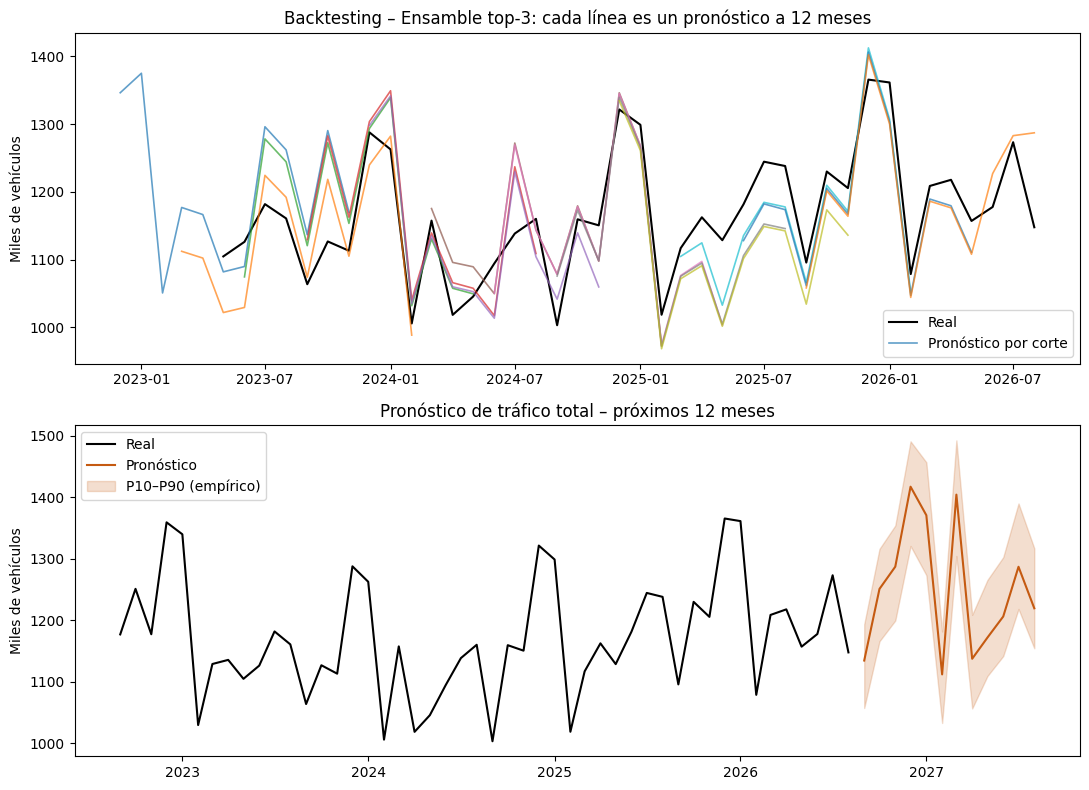

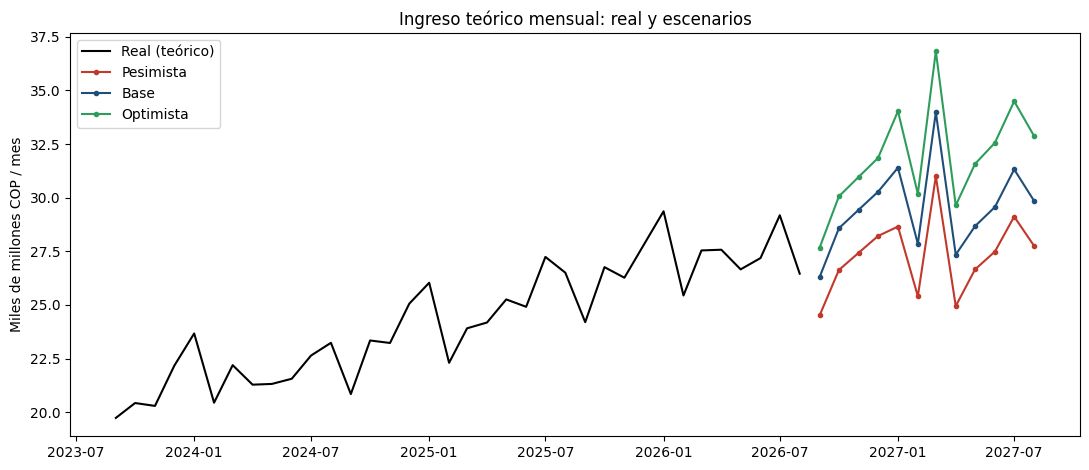

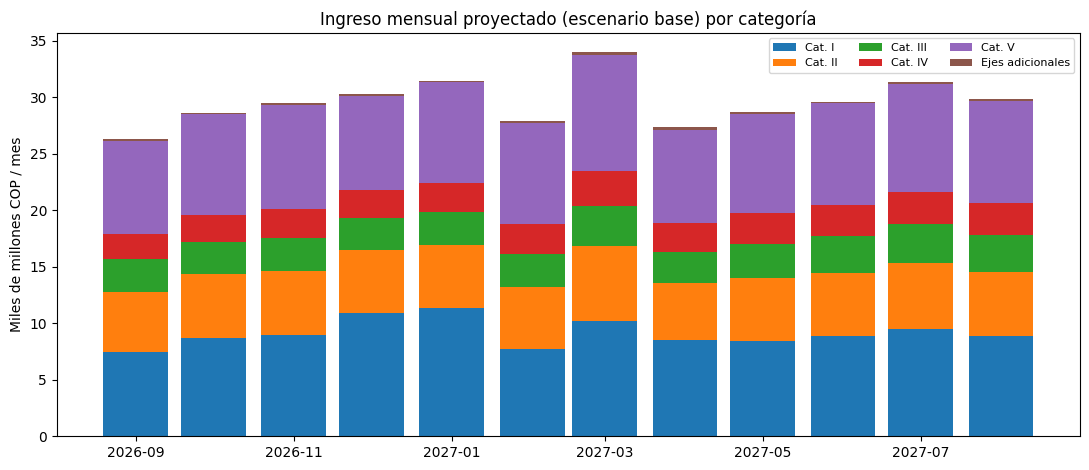

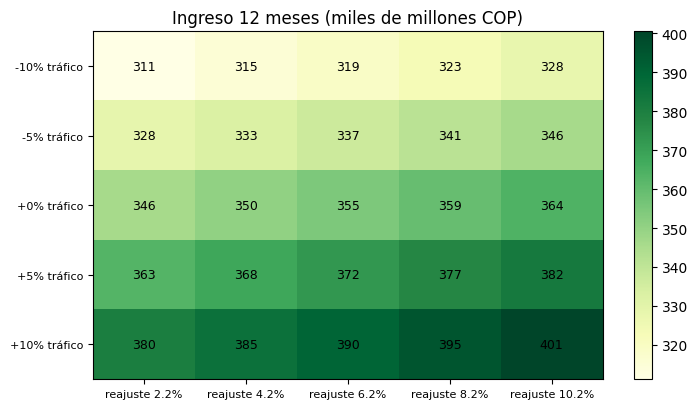

Resultados exportados a /content/resultados


In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(11, 8))
bb = bt[bt["modelo"] == mejor]
ax[0].plot(d.index[-40:], d["trafico_total"].values[-40:] / 1e3, color="black", label="Real")
for i, (c, gdf) in enumerate(bb.groupby("corte")):
    ax[0].plot(gdf["fecha"], gdf["pred"] / 1e3, alpha=.7, lw=1.2, label="Pronóstico por corte" if i == 0 else None)
ax[0].set_title(f"Backtesting – {mejor}: cada línea es un pronóstico a 12 meses"); ax[0].set_ylabel("Miles de vehículos"); ax[0].legend()
ax[1].plot(d.index[-48:], d["trafico_total"].values[-48:] / 1e3, color="black", label="Real")
ax[1].plot(fc["fecha"], fc["trafico_pred"] / 1e3, color="#c55a11", label="Pronóstico")
ax[1].fill_between(fc["fecha"], fc["p10"] / 1e3, fc["p90"] / 1e3, color="#c55a11", alpha=.2, label="P10–P90 (empírico)")
ax[1].set_title("Pronóstico de tráfico total – próximos 12 meses"); ax[1].set_ylabel("Miles de vehículos"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig3_backtest_y_pronostico.png", dpi=130); plt.show()

# >>> NUEVO: escenarios de ingreso
fig, ax = plt.subplots(figsize=(11, 4.8))
hh = m.loc[d.index[-1] - pd.DateOffset(months=35):d.index[-1], "ingreso_teorico"] / 1e9
ax.plot(hh.index, hh.values, color="black", label="Real (teórico)")
for nom, col in [("Pesimista", "#c0392b"), ("Base", "#1f4e79"), ("Optimista", "#2e9d5b")]:
    ax.plot(fc["fecha"], det_esc[nom].sum(axis=1) / 1e9, color=col, marker="o", ms=3, label=nom)
ax.set_ylabel("Miles de millones COP / mes"); ax.set_title("Ingreso teórico mensual: real y escenarios"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig4_escenarios_ingresos.png", dpi=130); plt.show()

# >>> NUEVO: ingreso base por categoría
fig, ax = plt.subplots(figsize=(11, 4.8))
bottom = np.zeros(len(cat_base))
for c in cat_base.columns:
    ax.bar(cat_base.index, cat_base[c] / 1e9, bottom=bottom, width=25, label=c); bottom += cat_base[c].values / 1e9
ax.set_ylabel("Miles de millones COP / mes"); ax.set_title("Ingreso mensual proyectado (escenario base) por categoría"); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig5_ingresos_categoria.png", dpi=130); plt.show()

# >>> NUEVO: sensibilidad
fig, ax = plt.subplots(figsize=(7.5, 4.2))
im = ax.imshow(sens.values, cmap="YlGn", aspect="auto")
ax.set_xticks(range(sens.shape[1])); ax.set_xticklabels(sens.columns, fontsize=8)
ax.set_yticks(range(sens.shape[0])); ax.set_yticklabels(sens.index, fontsize=8)
for i in range(sens.shape[0]):
    for j in range(sens.shape[1]):
        ax.text(j, i, f"{sens.values[i, j]:.0f}", ha="center", va="center", fontsize=9)
ax.set_title("Ingreso 12 meses (miles de millones COP)"); plt.colorbar(im)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig6_sensibilidad.png", dpi=130); plt.show()

fc.round(0).to_csv(f"{OUT_DIR}/pronostico_trafico_ingresos.csv", index=False)
with pd.ExcelWriter(f"{OUT_DIR}/resultados_modelos.xlsx") as w:
    metricas.reset_index().to_excel(w, sheet_name="metricas", index=False)
    metricas_hold.reset_index().to_excel(w, sheet_name="metricas_holdout", index=False)               # >>> NUEVO
    tabla_abl.round(2).reset_index().to_excel(w, sheet_name="ablacion", index=False)                  # >>> MODIFICADO (nombre y columnas)
    tabla_abl_h.round(2).reset_index().to_excel(w, sheet_name="ablacion_holdout", index=False)        # >>> NUEVO
    prueba_pareada.to_excel(w, sheet_name="prueba_pareada", index=False)                              # >>> NUEVO
    corr_ise.to_excel(w, sheet_name="corr_ise", index=False)                                          # >>> NUEVO
    fc.to_excel(w, sheet_name="pronostico", index=False)
    tabla_esc.reset_index().rename(columns={"index": "escenario"}).to_excel(w, sheet_name="escenarios", index=False)   # >>> NUEVO
    sens.round(2).reset_index().to_excel(w, sheet_name="sensibilidad", index=False)                   # >>> NUEVO
    cat_base.reset_index().rename(columns={"index": "fecha"}).to_excel(w, sheet_name="ingreso_categoria_base", index=False)  # >>> NUEVO
    bt.drop(columns=["err", "ape"]).to_excel(w, sheet_name="backtest_detalle", index=False)
print("Resultados exportados a", OUT_DIR)